In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest

print("Libraries imported successfully!")

ModuleNotFoundError: No module named 'seaborn'

In [2]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
df = pd.read_csv("../Week2/superstore_csv.csv")

print("Dataset loaded successfully!")

print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (9994, 9)


,Order Date,Region,State,Category,Sub-Category,Segment,Sales,Profit,Quantity
0,11/8/2016,South,Kentucky,Furniture,Bookcases,Consumer,261.9600,41.9136,2
1,11/8/2016,South,Kentucky,Furniture,Chairs,Consumer,731.9400,219.5820,3
2,6/12/2016,West,California,Office Supplies,Labels,Corporate,14.6200,6.8714,2
3,10/11/2015,South,Florida,Furniture,Tables,Consumer,957.5775,-383.0310,5
4,10/11/2015,South,Florida,Office Supplies,Storage,Consumer,22.3680,2.5164,2


In [5]:
X = df[["Sales", "Profit", "Quantity"]].copy()

print("Selected features:")
print(X.head())

print("\nMissing values:")
print(X.isnull().sum())

Selected features:
      Sales    Profit  Quantity
0  261.9600   41.9136         2
1  731.9400  219.5820         3
2   14.6200    6.8714         2
3  957.5775 -383.0310         5
4   22.3680    2.5164         2

Missing values:
Sales       0
Profit      0
Quantity    0
dtype: int64


In [6]:
X = X.fillna(X.median())

print("Missing values handled!")

Missing values handled!


In [7]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature scaling completed!")
print("Scaled data shape:", X_scaled.shape)

Feature scaling completed!
Scaled data shape: (9994, 3)


In [8]:
inertia_values = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia_values.append(kmeans.inertia_)

print("Inertia values:", inertia_values)

Inertia values: [29982.000000000022, 22548.630054432124, 15755.835191995862, 12495.014725030085, 10362.171276674315, 8917.770593023633, 7585.675818808629, 6708.832825238813, 6049.147285450704, 5406.4449249027875]


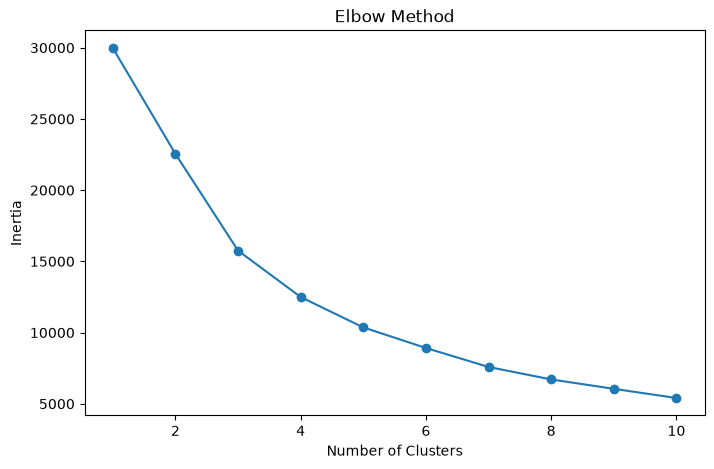

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), inertia_values, marker="o")

plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()

In [10]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

df["Cluster"] = clusters

print("Clustering completed!")
print(df["Cluster"].value_counts().sort_index())

Clustering completed!
Cluster
0    6790
1      27
2    3177
Name: count, dtype: int64


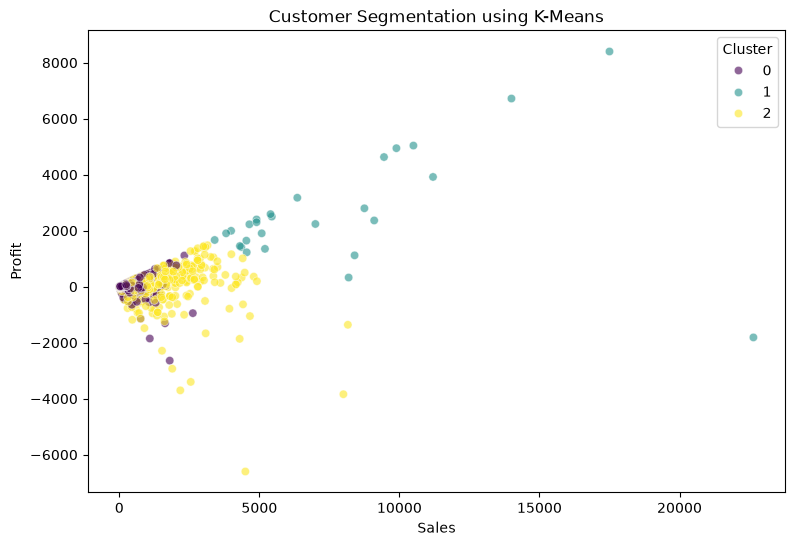

In [11]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Sales",
    y="Profit",
    hue="Cluster",
    palette="viridis",
    alpha=0.6
)

plt.title("Customer Segmentation using K-Means")
plt.show()

In [12]:
cluster_profile = df.groupby("Cluster").agg(
    Total_Records=("Sales", "count"),
    Average_Sales=("Sales", "mean"),
    Average_Profit=("Profit", "mean"),
    Average_Quantity=("Quantity", "mean")
).round(2)

print(cluster_profile)

         Total_Records  Average_Sales  Average_Profit  Average_Quantity
Cluster                                                                
0                 6790         125.12           13.46              2.54
1                   27        7685.18         2610.22              5.19
2                 3177         390.36           39.20              6.44


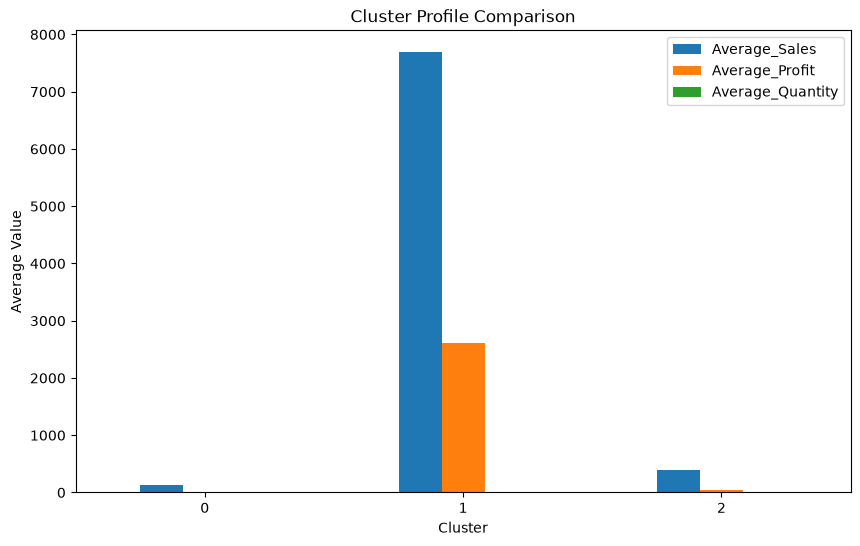

In [13]:
cluster_profile[[
    "Average_Sales",
    "Average_Profit",
    "Average_Quantity"
]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Cluster Profile Comparison")
plt.xlabel("Cluster")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.legend()
plt.show()

In [14]:
from sklearn.decomposition import PCA

# Reduce 3 features into 2 components
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original shape:", X_scaled.shape)
print("Reduced shape:", X_pca.shape)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:",
      pca.explained_variance_ratio_.sum())

Original shape: (9994, 3)
Reduced shape: (9994, 2)
Explained variance ratio: [0.51516862 0.31771377]
Total explained variance: 0.8328823828027094


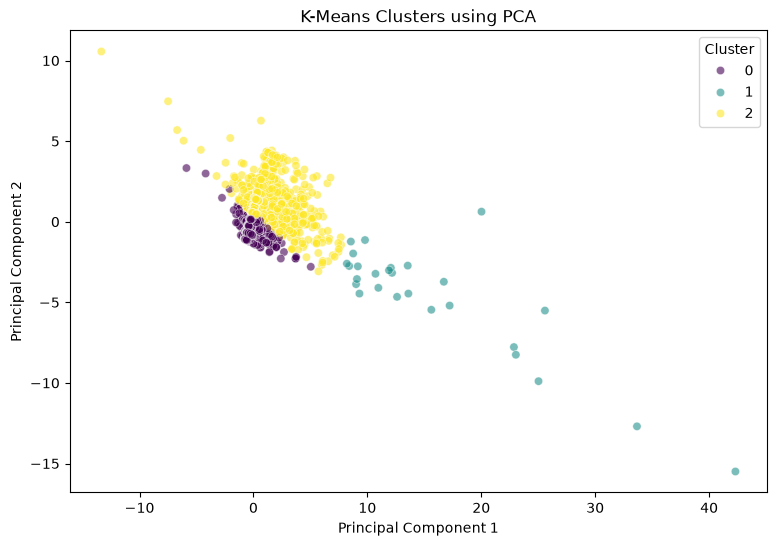

In [15]:
pca_df = pd.DataFrame(
    X_pca,
    columns=["Principal Component 1", "Principal Component 2"]
)

pca_df["Cluster"] = df["Cluster"].values

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_df,
    x="Principal Component 1",
    y="Principal Component 2",
    hue="Cluster",
    palette="viridis",
    alpha=0.6
)

plt.title("K-Means Clusters using PCA")
plt.show()

In [16]:
from sklearn.ensemble import IsolationForest

# Create the model
iso_forest = IsolationForest(
    contamination=0.01,
    random_state=42
)

# Detect anomalies
anomaly_predictions = iso_forest.fit_predict(X_scaled)

# Store results in dataframe
df["Anomaly"] = anomaly_predictions

print("Anomaly detection completed!")


Anomaly detection completed!


In [17]:
print("Anomaly counts:")
print(df["Anomaly"].value_counts())

print("\nNumber of anomalies:",
      (df["Anomaly"] == -1).sum())

print("Number of normal records:",
      (df["Anomaly"] == 1).sum())

Anomaly counts:
Anomaly
 1    9894
-1     100
Name: count, dtype: int64

Number of anomalies: 100
Number of normal records: 9894


In [18]:
anomalies = df[df["Anomaly"] == -1]

print("First 10 detected anomalies:")

display(
    anomalies[
        ["Region", "Category", "Sub-Category",
         "Sales", "Profit", "Quantity", "Anomaly"]
    ].head(10)
)

First 10 detected anomalies:


,Region,Category,Sub-Category,Sales,Profit,Quantity,Anomaly
27,East,Furniture,Bookcases,3083.430,-1665.0522,7,-1
165,Central,Technology,Machines,8159.952,-1359.9920,8,-1
251,West,Technology,Accessories,3347.370,636.0003,13,-1
262,Central,Technology,Machines,3059.982,-509.9970,3,-1
318,East,Technology,Machines,3991.980,1995.9900,2,-1
353,East,Office Supplies,Binders,4355.168,1415.4296,4,-1
509,South,Office Supplies,Binders,6354.950,3177.4750,5,-1
515,West,Technology,Copiers,2999.950,1379.9770,5,-1
683,South,Technology,Machines,7999.980,-3839.9904,4,-1
949,East,Furniture,Tables,2065.320,-619.5960,12,-1


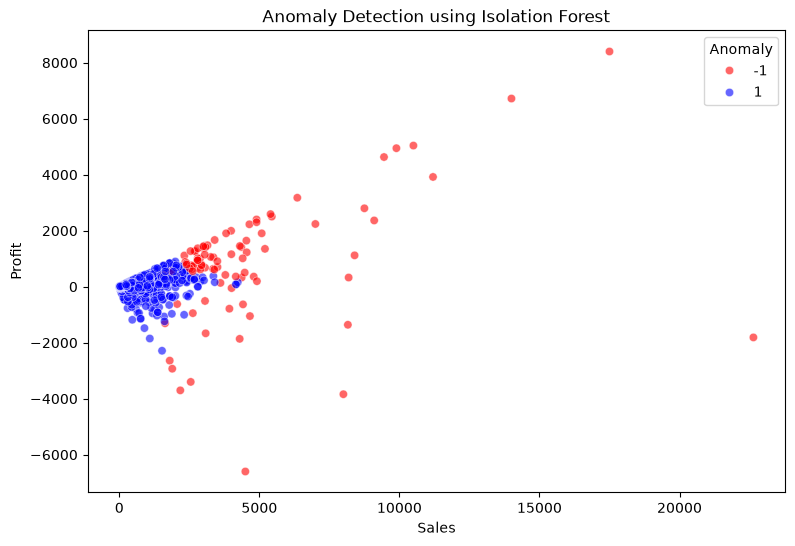

In [19]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Sales",
    y="Profit",
    hue="Anomaly",
    palette={1: "blue", -1: "red"},
    alpha=0.6
)

plt.title("Anomaly Detection using Isolation Forest")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.show()

In [20]:
# Calculate anomaly scores
df["Anomaly_Score"] = iso_forest.decision_function(X_scaled)

# Get the 3 most unusual records
top_anomalies = (
    df[df["Anomaly"] == -1]
    .sort_values("Anomaly_Score")
    .head(3)
)

display(
    top_anomalies[
        ["Region", "Category", "Sub-Category",
         "Sales", "Profit", "Quantity", "Anomaly_Score"]
    ]
)

,Region,Category,Sub-Category,Sales,Profit,Quantity,Anomaly_Score
9039,Central,Office Supplies,Binders,9892.74,4946.3700,13,-0.124041
6826,Central,Technology,Copiers,17499.95,8399.9760,5,-0.104852
8153,West,Technology,Copiers,13999.96,6719.9808,4,-0.104294
